# AIP304 Coursework 2 — Option 2
## Day 1: reproducible data preparation
**Team:** TODO: names, student IDs and contributions.  
**Question:** Does lesion-mask supervision improve rejection of unknown host–disease pairs relative to a matched RGB classifier? All evaluated predictions use RGB only.

This notebook prepares PlantSeg **v7**, audits the nine-host subset, and constructs Assignments A/B. It does not train models or compute test performance. Run cells in order on CPU. Saved outputs describe the actual run; protocol status remains **draft** until anomalies and team decisions are resolved.

Sources: local *AIP304 CW2 Task Sheet.pdf*, pp. 2, 4–8; [versioned dataset](https://zenodo.org/records/17719108); [dataset descriptor](https://doi.org/10.1038/s41597-025-06513-4). Data/source licences must be preserved; raw images are not committed to Git.

## 1. Environment and paths
Install dependencies separately if needed: `%pip install pandas numpy Pillow matplotlib nbformat nbclient ipykernel`.

Start Jupyter from the CW2 folder. On Colab/Kaggle, set `CW2_PROJECT_ROOT` to a writable output folder and optionally `PLANTSEG_DATA_ROOT` to the existing directory containing `Metadata.csv`, `images/`, and `annotations/`. Manual data without the verified release archive is audited but cannot be marked source-verified. The archive can be placed at `data/raw/plantseg.zip` before running. No GPU or training framework is needed today.

In [1]:
from pathlib import Path, PurePosixPath
from datetime import datetime, timezone, timedelta
from collections import Counter
import os, sys, json, hashlib, zipfile, shutil, stat, zlib, time, platform
import urllib.request
import importlib.metadata
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
from IPython.display import display

START_TIME = time.perf_counter()
PROJECT_ROOT = Path(os.environ.get('CW2_PROJECT_ROOT', '.')).resolve()
RAW = PROJECT_ROOT / 'data' / 'raw'
ART = PROJECT_ROOT / 'artifacts'
for folder in [RAW, ART/'metadata', ART/'audit', ART/'splits', ART/'figures']:
    folder.mkdir(parents=True, exist_ok=True)
DATA_ROOT = Path(os.environ.get('PLANTSEG_DATA_ROOT', str(RAW/'plantseg-v7'/'plantseg'))).resolve()
DOWNLOAD = True  # Set False to work offline with an existing archive/data directory.
SEED = 304
HOSTS = ('apple', 'banana', 'citrus', 'corn', 'potato', 'soybean', 'tomato', 'wheat', 'zucchini')
SPLITS = ('training', 'validation', 'test')
RECORD_ID = 17719108
RECORD_URL = f'https://zenodo.org/records/{RECORD_ID}'
API_URL = f'https://zenodo.org/api/records/{RECORD_ID}'
# Official checksum read from the fixed v7 record; never inferred from local data.
SOURCE_MD5 = '9358a66dff88cdd15c4fe009763c40a3'
SOURCE_SIZE = 1057281724
RUN_AT = datetime.now(timezone(timedelta(hours=8))).isoformat()

def save_json(path, value):
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False)+'\n', encoding='utf-8')

def save_csv(frame, path):
    frame.to_csv(path, index=False, lineterminator='\n')

def digest_file(path, algorithm='sha256'):
    h = hashlib.new(algorithm)
    with Path(path).open('rb') as f:
        for block in iter(lambda: f.read(1024*1024), b''):
            h.update(block)
    return h.hexdigest()

environment = {'run_at': RUN_AT, 'python': sys.version, 'platform': platform.platform(),
               'display_seed': SEED, 'hardware': platform.machine(), 'device': 'CPU',
               'packages': {p: importlib.metadata.version(p) for p in
                            ['pandas','numpy','Pillow','matplotlib','nbformat','nbclient','ipykernel']}}
save_json(ART/'metadata'/'environment.json', environment)
display(environment)

{'run_at': '2026-11-11T22:37:49.184325+08:00',
 'python': '3.14.7 | packaged by Anaconda, Inc. | (main, Aug 14 2026, 10:13:42) [Clang 20.1.8 ]',
 'platform': 'macOS-26.5-arm64-arm-64bit-Mach-O',
 'display_seed': 304,
 'hardware': 'arm64',
 'device': 'CPU',
 'packages': {'pandas': '3.0.5',
  'numpy': '2.5.2',
  'Pillow': '12.3.0',
  'matplotlib': '3.11.1',
  'nbformat': '5.11.0',
  'nbclient': '0.11.0',
  'ipykernel': '7.3.0'}}

## 2. Download, verify and safely extract v7
The official MD5 is checked before extraction. SHA-256 is also recorded as a local fingerprint. Existing archives are reused only after verification. Downloads use a `.part` file, so interrupted downloads cannot masquerade as complete archives.

Extraction rejects traversal paths, symlinks and duplicate archive names. Existing extracted files are compared with ZIP size/CRC; mismatches stop execution rather than overwrite raw data. An external manual directory is compared against the verified archive where available. A ZIP CRC check is an integrity check, not a separate source-authenticity claim.

In [2]:
def get_source_record():
    cache = ART/'metadata'/'zenodo_record.json'
    if cache.exists():
        record = json.loads(cache.read_text())
        origin = 'cached official API response'
    else:
        with urllib.request.urlopen(API_URL, timeout=45) as response:
            record = json.load(response)
        origin = 'live official API response'
    if int(record['id']) != RECORD_ID:
        raise ValueError('Wrong Zenodo record')
    if record['metadata']['publication_date'] != '2025-11-25':
        raise ValueError('Unexpected publication date')
    files = [f for f in record['files'] if f['key'] == 'plantseg.zip']
    if len(files) != 1:
        raise ValueError('Expected exactly one plantseg.zip')
    entry = files[0]
    if entry['checksum'] != 'md5:'+SOURCE_MD5 or entry['size'] != SOURCE_SIZE:
        raise ValueError('Source metadata changed: review the fixed release before proceeding')
    save_json(cache, record)
    return entry, origin

def safe_relative(name):
    p = PurePosixPath(name)
    if p.is_absolute() or '..' in p.parts or '\\' in name or ':' in name:
        raise ValueError(f'Unsafe archive/path entry: {name}')
    return p

def safe_extract_or_verify(archive, destination, external=False):
    destination = Path(destination).resolve()
    with zipfile.ZipFile(archive) as z:
        entries = z.infolist()
        if len({e.filename for e in entries}) != len(entries):
            raise ValueError('Duplicate ZIP entries')
        # Validate the complete namespace before writing anything.
        for e in entries:
            safe_relative(e.filename)
            if stat.S_ISLNK(e.external_attr >> 16):
                raise ValueError('Symlink in archive')
        for e in entries:
            parts = safe_relative(e.filename).parts
            if external:
                if not parts or parts[0] != 'plantseg':
                    raise ValueError('Unexpected archive root')
                parts = parts[1:]
            target = destination.joinpath(*parts)
            if not target.resolve().is_relative_to(destination) or target.is_symlink():
                raise ValueError('Unsafe extraction target')
            if e.is_dir():
                if not external:
                    target.mkdir(parents=True, exist_ok=True)
                continue
            if target.exists():
                if target.stat().st_size != e.file_size:
                    raise ValueError(f'Existing raw file differs: {e.filename}')
                crc = 0
                with target.open('rb') as f:
                    for block in iter(lambda: f.read(1024*1024), b''):
                        crc = zlib.crc32(block, crc)
                if crc & 0xffffffff != e.CRC:
                    raise ValueError(f'Existing raw file CRC differs: {e.filename}')
            elif external:
                raise FileNotFoundError(f'Manual dataset incomplete: {e.filename}')
            else:
                target.parent.mkdir(parents=True, exist_ok=True)
                temporary = target.with_name(target.name+'.extracting')
                with z.open(e) as src, temporary.open('wb') as dst:
                    shutil.copyfileobj(src, dst)
                temporary.replace(target)

archive = RAW/'plantseg.zip'
dataset_info = {'version': 'v7', 'record_id': RECORD_ID, 'source_url': RECORD_URL,
                'publication_date': '2025-11-25', 'file_name': 'plantseg.zip',
                'checked_at': RUN_AT, 'checksum_status': 'unverified',
                'source_checksum': 'md5:'+SOURCE_MD5, 'source_expected_bytes': SOURCE_SIZE,
                'downloaded_at': None, 'local_sha256': None}
previous = ART/'metadata'/'dataset_info.json'
if previous.exists():
    dataset_info['downloaded_at'] = json.loads(previous.read_text()).get('downloaded_at')
try:
    file_entry, record_origin = get_source_record()
    dataset_info.update(download_url=file_entry['links']['self'], metadata_origin=record_origin)
    if not archive.exists() and DOWNLOAD:
        partial = archive.with_suffix('.zip.part')
        with urllib.request.urlopen(file_entry['links']['self'], timeout=90) as src, partial.open('wb') as dst:
            shutil.copyfileobj(src, dst, length=1024*1024)
        if partial.stat().st_size != SOURCE_SIZE or digest_file(partial,'md5') != SOURCE_MD5:
            raise ValueError('Downloaded archive failed source verification')
        partial.replace(archive)
        dataset_info['downloaded_at'] = RUN_AT
    if archive.exists():
        dataset_info['file_size_bytes'] = archive.stat().st_size
        dataset_info['local_md5'] = digest_file(archive,'md5')
        dataset_info['local_sha256'] = digest_file(archive)
        if archive.stat().st_size != SOURCE_SIZE or dataset_info['local_md5'] != SOURCE_MD5:
            dataset_info['checksum_status'] = 'failed'
            raise ValueError('Archive is not the verified v7 archive; do not use it')
        dataset_info['checksum_status'] = 'verified'
        if 'PLANTSEG_DATA_ROOT' in os.environ:
            safe_extract_or_verify(archive, DATA_ROOT, external=True)
        else:
            safe_extract_or_verify(archive, RAW/'plantseg-v7')
        dataset_info['extracted_files_status'] = 'verified against archive'
        if dataset_info['downloaded_at'] is None:
            dataset_info['download_date_note'] = 'Archive supplied before this run; original acquisition timestamp not recorded.'
    elif not DATA_ROOT.is_dir():
        raise FileNotFoundError('No dataset. Place plantseg.zip in data/raw or set PLANTSEG_DATA_ROOT.')
except Exception as exc:
    dataset_info['error'] = f'{type(exc).__name__}: {exc}'
    save_json(ART/'metadata'/'dataset_info.json', dataset_info)
    raise
save_json(ART/'metadata'/'dataset_info.json', dataset_info)
display(dataset_info)

{'version': 'v7',
 'record_id': 17719108,
 'source_url': 'https://zenodo.org/records/17719108',
 'publication_date': '2025-11-25',
 'file_name': 'plantseg.zip',
 'checked_at': '2026-11-11T22:37:49.184325+08:00',
 'checksum_status': 'verified',
 'source_checksum': 'md5:9358a66dff88cdd15c4fe009763c40a3',
 'source_expected_bytes': 1057281724,
 'downloaded_at': '2026-11-11T22:34:53.156157+08:00',
 'local_sha256': 'cbdfb273eb26fea93fda52bbfe4766cc31881feb3a1202b13e4d85e8a4c0bcfa',
 'download_url': 'https://zenodo.org/api/records/17719108/files/plantseg.zip/content',
 'metadata_origin': 'cached official API response',
 'file_size_bytes': 1057281724,
 'local_md5': '9358a66dff88cdd15c4fe009763c40a3',
 'extracted_files_status': 'verified against archive'}

## 3. Inspect the actual metadata and directory layout
The v7 archive was inspected before implementing this parser. It contains `plantseg/Metadata.csv`, `images/{train,val,test}`, `annotations/{train,val,test}`, and COCO JSON annotations. The CSV's `Name` is a globally unique official identifier in this release. `Plant`, `Disease`, `Index`, `Label file`, and `Split` supply the labels, mask pairing and partition; filenames are never predictive inputs.

`Disease` contains the host prefix (e.g. `apple black rot`). Normalisation strips surrounding/repeated whitespace, lowercases labels, and removes exactly the corresponding host prefix. Original values and source URL/licence are retained. Unexpected schemas or selected-label collisions stop the pipeline. Outside the nine-host subset, a nonmatching prefix (e.g. grape/grapevine) is retained unchanged rather than aliased.

In [3]:
def inspect_dataset_layout(root):
    if not root.is_dir():
        raise FileNotFoundError('Set DATA_ROOT to the directory containing Metadata.csv')
    return {'top_level': sorted(p.name for p in root.iterdir()),
            'image_examples': [p.relative_to(root).as_posix() for p in sorted((root/'images'/'train').glob('*'))[:3]],
            'annotation_examples': [p.relative_to(root).as_posix() for p in sorted((root/'annotations'/'train').glob('*'))[:3]]}

def normalise(text):
    return ' '.join(str(text).strip().lower().split())

def load_metadata(root):
    meta = pd.read_csv(root/'Metadata.csv', keep_default_na=False)
    expected = {'Name','Index','Plant','Disease','Resolution','Label file','Mask ratio','URL','License','Split'}
    if not expected.issubset(meta.columns):
        raise ValueError(f'Unexpected metadata fields: {meta.columns.tolist()}')
    if meta['Name'].duplicated().any() or meta['Name'].eq('').any():
        raise ValueError('Official image names must be nonempty and unique')
    if not set(meta['Split']).issubset({'Training','Validation','Test'}):
        raise ValueError('Unknown original split')
    meta['host_raw'], meta['disease_raw'] = meta['Plant'], meta['Disease']
    meta['host'] = meta['Plant'].map(normalise)
    diseases = []
    for host, label in zip(meta['host'], meta['Disease'].map(normalise)):
        prefix = host+' '
        if not label.startswith(prefix) and host in HOSTS:
            raise ValueError(f'Selected disease label lacks documented host prefix: {host}, {label}')
        # Non-coursework labels such as grape/grapevine remain unchanged, not silently aliased.
        diseases.append(label[len(prefix):] if label.startswith(prefix) else label)
    meta['disease'] = diseases
    mapping = meta[['host_raw','disease_raw','host','disease','Index']].drop_duplicates()
    if mapping.duplicated(['host','disease']).any() or mapping['Index'].duplicated().any():
        raise ValueError('Normalisation merged labels or class indices are ambiguous')
    save_csv(mapping, ART/'metadata'/'label_normalisation.csv')
    return meta

layout = inspect_dataset_layout(DATA_ROOT)
metadata = load_metadata(DATA_ROOT)
display(layout)
print('Metadata shape:', metadata.shape)
print('Source fields:', metadata.columns[:10].tolist())
display(metadata[['Name','Plant','Disease','Index','Label file','Split']].head(3))

{'top_level': ['Metadata.csv',
  'annotation_test.json',
  'annotation_train.json',
  'annotation_val.json',
  'annotations',
  'images'],
 'image_examples': ['images/train/apple_black_rot_1.jpg',
  'images/train/apple_black_rot_11.jpg',
  'images/train/apple_black_rot_12.jpg'],
 'annotation_examples': ['annotations/train/apple_black_rot_1.png',
  'annotations/train/apple_black_rot_11.png',
  'annotations/train/apple_black_rot_12.png']}

Metadata shape: (7774, 14)
Source fields: ['Name', 'Index', 'Plant', 'Disease', 'Resolution', 'Label file', 'Mask ratio', 'URL', 'License', 'Split']


,Name,Plant,Disease,Index,Label file,Split
0,apple_black_rot_1.jpg,Apple,apple black rot,0,apple_black_rot_1.png,Training
1,apple_black_rot_11.jpg,Apple,apple black rot,0,apple_black_rot_11.png,Training
2,apple_black_rot_12.jpg,Apple,apple black rot,0,apple_black_rot_12.png,Training


## 4. Build the nine-host image index
Class roles are built from the full selected metadata taxonomy before any exclusion. Relative paths and tuple keys `(host, disease)` prevent collisions. Missing files remain in the index and are reported by the audit; they are never silently dropped.

In [4]:
def build_image_index(meta):
    selected = meta.loc[meta.host.isin(HOSTS)].copy()
    if set(selected.host) != set(HOSTS):
        raise ValueError('One or more required hosts are missing')
    rows = []
    split_dir = {'Training':'train','Validation':'val','Test':'test'}
    for row in selected.to_dict('records'):
        for field in ['Name','Label file']:
            p = safe_relative(row[field])
            if len(p.parts) != 1:
                raise ValueError(f'Unexpected nested metadata filename: {row[field]}')
        folder = split_dir[row['Split']]
        rows.append({'image_id': row['Name'], 'image_path': f'images/{folder}/{row["Name"]}',
                     'mask_path': f'annotations/{folder}/{row["Label file"]}',
                     'host_raw':row['host_raw'], 'disease_raw':row['disease_raw'],
                     'host':row['host'], 'disease':row['disease'],
                     'class_name':row['host']+' :: '+row['disease'],
                     'source_class_index':int(row['Index']), 'original_split':row['Split'].lower(),
                     'source_url':row['URL'], 'source_license':row['License'],
                     'metadata_resolution':row['Resolution']})
    result = pd.DataFrame(rows).sort_values(['host','disease','original_split','image_id']).reset_index(drop=True)
    assert result.image_id.is_unique and result.image_path.is_unique
    return result

index = build_image_index(metadata)
classes = index[['host','disease','class_name','source_class_index']].drop_duplicates().sort_values(['host','disease']).reset_index(drop=True)
taxonomy_issues = []
if len(classes) != 43:
    taxonomy_issues.append(f'Expected 43 classes but actual metadata contains {len(classes)}')
print(f'Actual subset: {index.host.nunique()} hosts, {len(classes)} classes, {len(index)} images')
display(classes.groupby('host').size().rename('class_count').to_frame())
print('Taxonomy issues:', taxonomy_issues)

Actual subset: 9 hosts, 43 classes, 4349 images


,class_count
host,
apple,4
banana,6
citrus,2
corn,4
potato,2
soybean,6
tomato,7
wheat,8
zucchini,4


Taxonomy issues: []


## 5. Audit images, masks and exact duplicates
All partitions receive programmatic integrity checks; no validation/test image galleries are shown. File SHA-256 detects byte duplicates. Pixel SHA-256 includes original oriented dimensions and decoded RGB bytes after EXIF transpose, without resizing. Perceptual/near-duplicate checks are **not performed**, so exact checks cannot establish complete absence of leakage.

Mask evidence: the author's [115-class loader](https://github.com/tqwei05/PlantSeg/blob/main/mmseg/datasets/plantseg115.py) lists a blank background followed by the class taxonomy; the [binary loader](https://github.com/tqwei05/PlantSeg/blob/main/mmseg/datasets/plantseg_binary.py) defines background as zero. Inspected v7 PNGs use `{0, Index + 1}`. Every selected mask is checked against its own expected code before conversion by equality. Values such as 255 are treated as unexpected, never automatically as lesion. Nontrivial image EXIF orientation is flagged for alignment review, and those pairs cannot be used for mask supervision yet.

Mask issues exclude only affected **known training** examples, identically for both compared methods. Evaluation does not require a ground-truth mask. Cross-partition duplicates are retained as unresolved findings and prevent freezing; no images are moved.

In [5]:
def audit_images_and_masks(frame, root):
    audited, invalid, mask_issues = [], [], []
    for i, row in enumerate(frame.to_dict('records'), 1):
        item = dict(row)
        item.update(width=None, height=None, image_mode='', readable=False, exif_orientation=None,
                    file_sha256='', pixel_sha256='', image_error='', mask_exists=False,
                    mask_readable=False, mask_ok=False, mask_values='', mask_error='')
        image_path, mask_path = root/row['image_path'], root/row['mask_path']
        try:
            item['file_sha256'] = digest_file(image_path)
            with Image.open(image_path) as im:
                im.load()
                item.update(width=im.width, height=im.height, image_mode=im.mode,
                            exif_orientation=int(im.getexif().get(274,1)))
                rgb = ImageOps.exif_transpose(im).convert('RGB')
                h = hashlib.sha256()
                h.update(f'RGB:{rgb.width}x{rgb.height}:'.encode())
                h.update(rgb.tobytes())
                item['pixel_sha256'] = h.hexdigest()
                item['readable'] = True
        except Exception as exc:
            item['image_error'] = type(exc).__name__+': '+str(exc).replace(str(root),'DATA_ROOT')
            invalid.append({'image_id':row['image_id'], 'image_path':row['image_path'], 'reason':item['image_error']})
        issues = []
        item['mask_exists'] = mask_path.is_file()
        try:
            with Image.open(mask_path) as mask:
                mask.load()
                values = np.unique(np.asarray(mask)).tolist()
                item.update(mask_readable=True, mask_values=json.dumps(values), mask_mode=mask.mode,
                            mask_width=mask.width, mask_height=mask.height)
                if mask.mode not in ('L','P'):
                    issues.append('mask_not_single_channel_label_indices')
                if not set(values).issubset({0,row['source_class_index']+1}):
                    issues.append('unexpected_mask_codes')
                if row['source_class_index']+1 not in values:
                    issues.append('empty_lesion_mask')
                if item['readable'] and mask.size != (item['width'],item['height']):
                    issues.append('mask_image_size_mismatch')
                if item['readable'] and item['exif_orientation'] != 1:
                    issues.append('exif_alignment_requires_review')
        except Exception as exc:
            issues.append('mask_missing_or_unreadable:'+type(exc).__name__)
        item['mask_error'] = ';'.join(issues)
        item['mask_ok'] = not issues and item['readable']
        if issues:
            mask_issues.append({'image_id':row['image_id'], 'mask_path':row['mask_path'],
                                'original_split':row['original_split'], 'reason':item['mask_error']})
        audited.append(item)
        if i % 1000 == 0:
            print(f'Audited {i}/{len(frame)} images')
    return (pd.DataFrame(audited), pd.DataFrame(invalid, columns=['image_id','image_path','reason']),
            pd.DataFrame(mask_issues, columns=['image_id','mask_path','original_split','reason']))

def find_exact_duplicates(frame):
    rows = []
    for kind, column in [('file','file_sha256'),('pixel','pixel_sha256')]:
        valid = frame.loc[frame[column].ne('')]
        for value, group in valid.groupby(column):
            if len(group) < 2:
                continue
            cross = group.original_split.nunique() > 1
            for row in group.to_dict('records'):
                rows.append({'kind':kind,'group_id':value,'image_id':row['image_id'],
                             'host':row['host'],'disease':row['disease'],'original_split':row['original_split'],
                             'cross_partition':cross,'status':'unresolved; no automatic exclusion'})
    return pd.DataFrame(rows, columns=['kind','group_id','image_id','host','disease','original_split','cross_partition','status'])

index, invalid_files, mask_issues = audit_images_and_masks(index, DATA_ROOT)
duplicates = find_exact_duplicates(index)
cross_duplicates = duplicates.loc[duplicates.cross_partition.eq(True)].copy()
host_counts = index.groupby(['host','original_split']).size().unstack(fill_value=0).reindex(index=HOSTS, columns=SPLITS, fill_value=0)
class_counts = index.groupby(['host','disease','original_split']).size().unstack(fill_value=0).reindex(columns=SPLITS, fill_value=0)
exclusions = invalid_files[['image_id','reason']].assign(scope='all_assignments_all_splits')
mask_exclusions = mask_issues[['image_id','reason']].assign(scope='known_training_only_both_methods')
exclusions = pd.concat([exclusions,mask_exclusions],ignore_index=True)[['image_id','scope','reason']]
for frame, name in [(index,'../metadata/images.csv'),(host_counts.reset_index(),'host_counts.csv'),
                    (class_counts.reset_index(),'class_counts.csv'),(invalid_files,'invalid_files.csv'),
                    (mask_issues,'mask_issues.csv'),(duplicates,'duplicate_groups.csv'),
                    (cross_duplicates,'cross_partition_duplicates.csv'),(exclusions,'exclusions.csv')]:
    save_csv(frame, ART/'audit'/name)
# Count inventory discrepancies without using image appearance or inferred filenames as labels.
expected_images = set('images/'+{'training':'train','validation':'val','test':'test'}[r['Split'].lower()]+'/'+r['Name'] for r in metadata.to_dict('records'))
actual_images = set(p.relative_to(DATA_ROOT).as_posix() for p in (DATA_ROOT/'images').rglob('*') if p.is_file())
inventory = {'unlisted_image_files':sorted(actual_images-expected_images),
             'metadata_image_paths_missing':sorted(expected_images-actual_images)}
save_json(ART/'audit'/'inventory_discrepancies.json', inventory)
audit_summary = {'images':len(index),'hosts':int(index.host.nunique()),'classes':len(classes),
                 'unreadable_images':len(invalid_files),'mask_issues':len(mask_issues),
                 'file_duplicate_groups':int(duplicates.loc[duplicates.kind.eq('file'),'group_id'].nunique()),
                 'pixel_duplicate_groups':int(duplicates.loc[duplicates.kind.eq('pixel'),'group_id'].nunique()),
                 'cross_partition_duplicate_images':int(cross_duplicates.image_id.nunique()),
                 'near_duplicate_check':'not performed; unresolved near-duplicate leakage is a limitation',
                 'pixel_hash_policy':'EXIF transpose, RGB, original oriented dimensions plus raw pixel bytes; no resizing'}
save_json(ART/'audit'/'audit_summary.json', audit_summary)
display(host_counts)
display(class_counts)
display(audit_summary)
display(mask_issues.head(10))

Audited 1000/4349 images


Audited 2000/4349 images


Audited 3000/4349 images


Audited 4000/4349 images


original_split,training,validation,test
host,,,
apple,274,46,82
banana,244,36,74
citrus,291,42,83
corn,289,46,84
potato,103,16,27
soybean,356,46,98
tomato,460,74,133
wheat,798,137,231
zucchini,192,32,55


original_split                                training  validation  test
host     disease                                                        
apple    black rot                                  43           8    12
         mosaic virus                               52           8    13
         rust                                       64          12    22
         scab                                      115          18    35
banana   anthracnose                                35           6     9
         black leaf streak                          79          10    25
         bunchy top                                 56           9    13
         cigar end rot                              22           2     9
         cordana leaf spot                          19           3     8
         panama disease                             33           6    10
citrus   canker                                    225          33    65
         greening disease                           66           9    18
corn     gray leaf spot                             49          10    17
         northern leaf blight                       65           9    18
         rust                                       84          13    23
         smut                                       91          14    26
potato   early blight                               50           9     9
         late blight                                53           7    18
soybean  bacterial blight                           41           6    14
         brown spot                                 42           3    10
         downy mildew                               56           6    14
         frog eye leaf spot                        111          13    29
         mosaic                                     61          11    17
         rust                                       45           7    14
tomato   bacterial leaf spot                        64           9    17
         early blight                              103          16    34
         late blight                                84          14    19
         leaf mold                                  71          13    18
         mosaic virus                               29           5     9
         septoria leaf spot                         66          13    20
         yellow leaf curl virus                     43           4    16
wheat    bacterial leaf streak (black chaff)        53          11    19
         head scab                                 161          25    44
         leaf rust                                  53           7    15
         loose smut                                101          15    25
         powdery mildew                            119          24    35
         septoria blotch                            95          19    28
         stem rust                                  56          11    22
         stripe rust                               160          25    43
zucchini bacterial wilt                             38           7    12
         downy mildew                               25           3     5
         powdery mildew                             90          16    27
         yellow mosaic virus                        39           6    11

{'images': 4349,
 'hosts': 9,
 'classes': 43,
 'unreadable_images': 0,
 'mask_issues': 10,
 'file_duplicate_groups': 161,
 'pixel_duplicate_groups': 162,
 'cross_partition_duplicate_images': 151,
 'near_duplicate_check': 'not performed; unresolved near-duplicate leakage is a limitation',
 'pixel_hash_policy': 'EXIF transpose, RGB, original oriented dimensions plus raw pixel bytes; no resizing'}

,image_id,mask_path,original_split,reason
0,apple_rust_google_0065.jpg,annotations/train/apple_rust_google_0065.png,training,mask_image_size_mismatch;exif_alignment_requir...
1,potato_late_blight_87.jpg,annotations/train/potato_late_blight_87.png,training,exif_alignment_requires_review
2,potato_late_blight_google_0038.jpg,annotations/train/potato_late_blight_google_00...,training,exif_alignment_requires_review
3,tomato_bacterial_leaf_spot_42.jpg,annotations/train/tomato_bacterial_leaf_spot_4...,training,mask_image_size_mismatch;exif_alignment_requir...
4,tomato_early_blight_google_0000.jpg,annotations/test/tomato_early_blight_google_00...,test,mask_image_size_mismatch;exif_alignment_requir...
5,tomato_early_blight_google_0056.jpg,annotations/test/tomato_early_blight_google_00...,test,mask_image_size_mismatch;exif_alignment_requir...
6,tomato_early_blight_google_0247.jpg,annotations/test/tomato_early_blight_google_02...,test,exif_alignment_requires_review
7,tomato_early_blight_google_0043.jpg,annotations/train/tomato_early_blight_google_0...,training,mask_image_size_mismatch;exif_alignment_requir...
8,tomato_septoria_leaf_spot_google_0033.jpg,annotations/test/tomato_septoria_leaf_spot_goo...,test,mask_image_size_mismatch;exif_alignment_requir...
9,wheat_head_scab_Bing_0287.jpg,annotations/test/wheat_head_scab_Bing_0287.png,test,unexpected_mask_codes;empty_lesion_mask


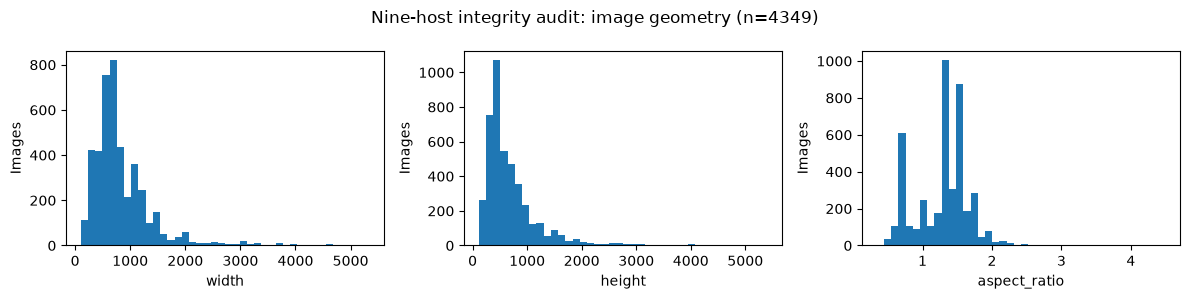

In [6]:
readable = index.loc[index.readable].copy()
readable['aspect_ratio'] = readable.width/readable.height
size_summary = readable[['width','height','aspect_ratio']].describe()
save_csv(size_summary.reset_index(names='statistic'), ART/'audit'/'image_size_summary.csv')
fig, axes = plt.subplots(1,3,figsize=(12,3))
for ax, col in zip(axes,['width','height','aspect_ratio']):
    ax.hist(readable[col],bins=40)
    ax.set(xlabel=col,ylabel='Images')
fig.suptitle(f'Nine-host integrity audit: image geometry (n={len(readable)})')
fig.tight_layout()
fig.savefig(ART/'figures'/'image_geometry.png',dpi=120)
plt.show()
plt.close(fig)

## 6. Deterministic class-role mappings for A/B
Sort the normalised disease strings by Python's Unicode code-point order (all current labels are lowercase English). Citrus is always development unknown; potato is always test unknown. For the other hosts, A holds out positions 1/2, and B positions 2/3. Each assignment has its own consecutive known-class IDs; unknown classes have no classifier output ID.

The `disease_shared_with_known` flag compares exact normalised disease labels across other known hosts. Synonyms are not merged.

In [7]:
def build_class_roles(class_table, assignment):
    if assignment not in ('A','B'):
        raise ValueError('Assignment must be A or B')
    result = class_table.copy().sort_values(['host','disease']).reset_index(drop=True)
    roles, ranks = [], []
    for host, group in result.groupby('host', sort=True):
        diseases = sorted(group.disease)
        if host not in ('citrus','potato') and len(diseases) < 3:
            raise ValueError(f'Insufficient classes for assignment B: {host}')
        for disease in group.disease:
            rank = diseases.index(disease)
            if host == 'citrus': role = 'development_unknown'
            elif host == 'potato': role = 'test_unknown'
            elif rank == (0 if assignment == 'A' else 1): role = 'development_unknown'
            elif rank == (1 if assignment == 'A' else 2): role = 'test_unknown'
            else: role = 'known'
            roles.append(role); ranks.append(rank+1)
    result['assignment'], result['disease_sort_position'], result['class_role'] = assignment, ranks, roles
    result['known_class_id'] = pd.array([pd.NA]*len(result),dtype='Int64')
    known = result.class_role.eq('known')
    result.loc[known,'known_class_id'] = np.arange(int(known.sum()))
    result['unknown_group'] = ['known' if r=='known' else 'unfamiliar_host' if h in ('citrus','potato') else 'familiar_host'
                               for h,r in zip(result.host,result.class_role)]
    shared = []
    for row in result.itertuples():
        if row.unknown_group == 'familiar_host':
            shared.append(bool((known & result.host.ne(row.host) & result.disease.eq(row.disease)).any()))
        else: shared.append(pd.NA)
    result['disease_shared_with_known'] = pd.array(shared,dtype='boolean')
    assert not result.duplicated(['host','disease']).any()
    assert result.loc[result.host.eq('citrus'),'class_role'].eq('development_unknown').all()
    assert result.loc[result.host.eq('potato'),'class_role'].eq('test_unknown').all()
    expected = {'A':['development_unknown','test_unknown','known','known'],
                'B':['known','development_unknown','test_unknown','known']}[assignment]
    apple = result.loc[result.host.eq('apple')].set_index('disease')
    assert set(apple.index)=={'black rot','mosaic virus','rust','scab'}, 'Apple labels conflict with task sheet'
    assert apple.loc[['black rot','mosaic virus','rust','scab'],'class_role'].tolist()==expected
    return result

roles = {a:build_class_roles(classes,a) for a in ('A','B')}
for a, table in roles.items():
    save_csv(table, ART/'splits'/f'class_roles_{a}.csv')
    save_csv(table.loc[table.class_role.eq('known'),['known_class_id','host','disease']], ART/'splits'/f'known_class_ids_{a}.csv')
    print('Assignment',a)
    display(table.groupby('class_role').size().rename('classes').to_frame())
save_json(ART/'splits'/'disease_sort_order.json', {host:sorted(group.disease) for host,group in classes.groupby('host')})
display(roles['A'].loc[roles['A'].host.eq('apple'),['host','disease','class_role','known_class_id']])

Assignment A


,classes
class_role,
development_unknown,9
known,25
test_unknown,9


Assignment B


,classes
class_role,
development_unknown,9
known,25
test_unknown,9


,host,disease,class_role,known_class_id
0,apple,black rot,development_unknown,<NA>
1,apple,mosaic virus,test_unknown,<NA>
2,apple,rust,known,0
3,apple,scab,known,1


## 7. Image-level manifests and protocol assertions
A row is usable only when **both** its `experimental_split` matches the requested split and `included=True`. Reserved-class images outside their permitted original partition are marked `unused`. Ground-truth mask access is allowed only for included known training rows.

Draft manifests are reproducible review artefacts, not permission to begin training. The notebook deliberately does not auto-freeze the experiment: duplicate decisions and the team protocol must be reviewed first. It records content hashes for all mappings/manifests.

In [8]:
def build_manifest(frame, role_table):
    columns = ['host','disease','assignment','class_role','known_class_id','unknown_group','disease_shared_with_known']
    m = frame.merge(role_table[columns],on=['host','disease'],how='left',validate='many_to_one')
    assert m.class_role.notna().all()
    m['experimental_split'] = 'unused'
    known = m.class_role.eq('known')
    m.loc[known,'experimental_split'] = m.loc[known,'original_split'].replace({'training':'train'})
    m.loc[m.class_role.eq('development_unknown') & m.original_split.eq('validation'),'experimental_split'] = 'validation'
    m.loc[m.class_role.eq('test_unknown') & m.original_split.eq('test'),'experimental_split'] = 'test'
    reasons = []
    for r in m.itertuples():
        flags = []
        if r.experimental_split == 'unused': flags.append('reserved_class_original_partition_not_used')
        if not r.readable: flags.append('image_missing_or_unreadable')
        if r.experimental_split == 'train' and not r.mask_ok: flags.append('training_mask_issue:'+r.mask_error)
        reasons.append(';'.join(flags))
    m['exclusion_reason'] = reasons
    m['included'] = m.exclusion_reason.eq('')
    m['mask_supervision_allowed'] = m.included & known & m.experimental_split.eq('train')
    return m.sort_values('image_id').reset_index(drop=True)

def validate_manifest(m, role_table, original):
    assert len(m) == len(original) and m.image_id.is_unique
    assert set(m.host)==set(HOSTS)
    expected = original.set_index('image_id').original_split
    assert m.set_index('image_id').original_split.sort_index().equals(expected.sort_index())
    assert m.loc[m.included,'readable'].all()
    assert not m.loc[m.experimental_split.eq('unused'),'included'].any()
    train = m.loc[m.included & m.experimental_split.eq('train')]
    assert train.class_role.eq('known').all() and train.original_split.eq('training').all()
    assert train.mask_ok.all()
    for role, split in [('development_unknown','validation'),('test_unknown','test')]:
        active = m.loc[m.included & m.class_role.eq(role)]
        assert active.experimental_split.eq(split).all() and active.original_split.eq(split).all()
    expected_mask = m.included & m.class_role.eq('known') & m.original_split.eq('training')
    assert m.mask_supervision_allowed.equals(expected_mask)
    assert m.loc[m.class_role.ne('known'),'known_class_id'].isna().all()
    ids = sorted(role_table.known_class_id.dropna().astype(int))
    assert ids == list(range(len(ids)))
    assert m.loc[m.class_role.eq('known'),'known_class_id'].notna().all()
    assert m.loc[~m.included,'exclusion_reason'].ne('').all()
    assert all(not PurePosixPath(p).is_absolute() for p in m.image_path)
    support = train.groupby(['host','disease']).size()
    expected_known = pd.MultiIndex.from_frame(role_table.loc[role_table.class_role.eq('known'),['host','disease']])
    support = support.reindex(expected_known,fill_value=0).rename('training_support').reset_index()
    return support

manifests, support_tables = {}, {}
blockers = list(taxonomy_issues)
if dataset_info['checksum_status'] != 'verified': blockers.append('Dataset source not verified')
if len(cross_duplicates): blockers.append('Cross-partition exact duplicate groups unresolved')
if len(invalid_files): blockers.append('Unreadable-image exclusions require review')
if len(mask_issues): blockers.append('Training-mask exclusions/alignment require review')
if any(inventory.values()): blockers.append('Dataset inventory discrepancies require review')
blockers.append('Team review and explicit protocol freeze pending')
for a in ('A','B'):
    m = build_manifest(index,roles[a])
    support = validate_manifest(m,roles[a],index)
    manifests[a], support_tables[a] = m, support
    save_csv(m,ART/'splits'/f'manifest_{a}.csv')
    save_csv(support,ART/'splits'/f'training_support_{a}.csv')
    if support.training_support.eq(0).any(): blockers.append(f'Assignment {a}: known class has zero training support')
    expected_groups = pd.MultiIndex.from_tuples([
        ('train','known'),('validation','known'),('validation','familiar_host'),
        ('validation','unfamiliar_host'),('test','known'),('test','familiar_host'),('test','unfamiliar_host')],
        names=['experimental_split','unknown_group'])
    counts = m.loc[m.included].groupby(['experimental_split','unknown_group']).size().reindex(expected_groups,fill_value=0).rename('images').reset_index()
    save_csv(counts,ART/'splits'/f'group_counts_{a}.csv')
    # Also preserve zero-support class x experimental-split cells for later reporting.
    eval_support = (m.loc[m.included].groupby(['host','disease','experimental_split']).size()
                    .unstack(fill_value=0).reindex(pd.MultiIndex.from_frame(classes[['host','disease']]),fill_value=0)
                    .reindex(columns=['train','validation','test'],fill_value=0))
    save_csv(eval_support.reset_index(),ART/'splits'/f'class_support_{a}.csv')
    if counts.images.eq(0).any(): blockers.append(f'Assignment {a}: an evaluation/training group is empty')
    print('Assignment',a,'included:',int(m.included.sum()),'unused/excluded:',int((~m.included).sum()))
    display(counts)

protocol_files = [p for p in (ART/'splits').glob('*.csv')]
protocol = {'status':'draft','dataset_version':'v7','record_id':RECORD_ID,
            'source_checksum_status':dataset_info['checksum_status'], 'created_at':RUN_AT,
            'sorting':'normalised lowercase disease; Unicode code-point ascending; remove exact host prefix',
            'original_partition_policy':'preserved; no random splitting or cross-partition transfers',
            'exclusion_policy':'unreadable images excluded globally; mask issues excluded for known training in both methods; duplicates unresolved',
            'mask_policy':'only included known training; label equality to source_class_index+1, background 0',
            'inference_inputs':'RGB only; no ground-truth masks, host metadata or class-bearing filenames',
            'freeze_blockers':sorted(set(blockers)),
            'near_duplicates':'not checked; limitation',
            'file_sha256':{p.name:digest_file(p) for p in sorted(protocol_files)}}
save_json(ART/'splits'/'split_protocol.json',protocol)
print('Protocol assertions passed for A and B. Status:',protocol['status'])
display(protocol['freeze_blockers'])

Assignment A included: 2831 unused/excluded: 1518


,experimental_split,unknown_group,images
0,train,known,1762
1,validation,known,286
2,validation,familiar_host,57
3,validation,unfamiliar_host,42
4,test,known,508
5,test,familiar_host,149
6,test,unfamiliar_host,27


Assignment B included: 2615 unused/excluded: 1734


,experimental_split,unknown_group,images
0,train,known,1598
1,validation,known,266
2,validation,familiar_host,74
3,validation,unfamiliar_host,42
4,test,known,475
5,test,familiar_host,133
6,test,unfamiliar_host,27


Protocol assertions passed for A and B. Status: draft


['Cross-partition exact duplicate groups unresolved',
 'Team review and explicit protocol freeze pending',
 'Training-mask exclusions/alignment require review']

## 8. Known-training examples only
Choose a small reproducible sample from images permitted for mask supervision in **both** assignments. An explicit assertion enforces that condition. The display converts class-coded masks to binary equality masks; class codes are not shown to a model.

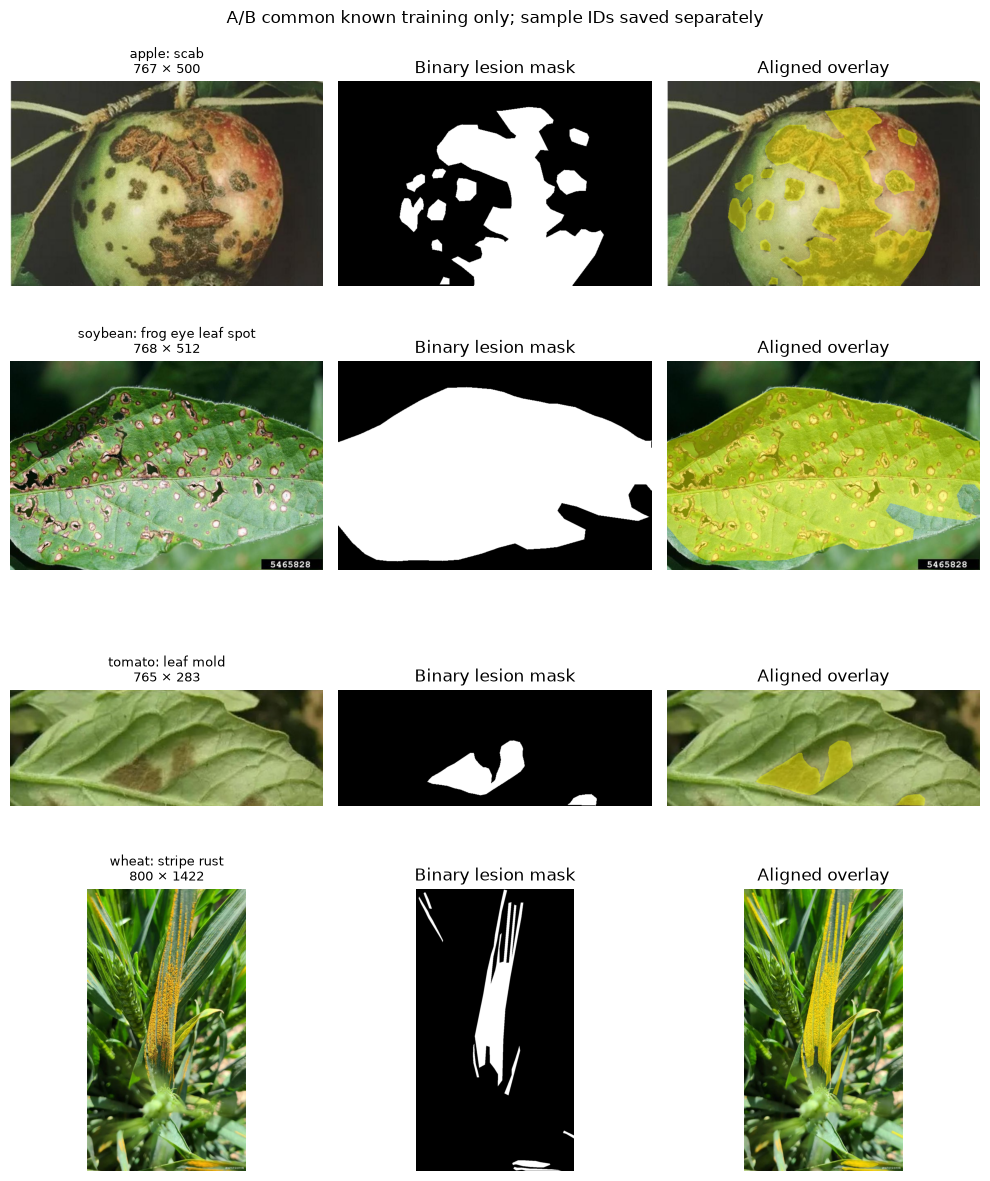

,image_id,host,disease
258,apple_scab_54.jpg,apple,scab
2010,soybean_frog_eye_leaf_spot_Bing_0146.jpg,soybean,frog eye leaf spot
2633,tomato_leaf_mold_204.jpg,tomato,leaf mold
3842,wheat_stripe_rust_Baidu_0000.jpg,wheat,stripe rust


In [9]:
def load_training_pair(row, root):
    if not (row['included'] and row['mask_supervision_allowed'] and row['class_role']=='known'
            and row['original_split']=='training' and row['experimental_split']=='train'):
        raise ValueError('Mask access is only permitted for included known training')
    with Image.open(root/row['image_path']) as source:
        if source.getexif().get(274,1) != 1:
            raise ValueError('EXIF alignment requires review before mask supervision')
        rgb = source.convert('RGB')
    with Image.open(root/row['mask_path']) as source:
        values = np.array(source)
    expected = int(row['source_class_index'])+1
    if values.ndim != 2 or not set(np.unique(values)).issubset({0,expected}):
        raise ValueError('Unexpected mask encoding')
    mask = Image.fromarray((values==expected).astype(np.uint8))
    if rgb.size != mask.size:
        raise ValueError('Image/mask geometry mismatch; do not hide with resize')
    return rgb, mask

common_ids = set(manifests['A'].loc[manifests['A'].mask_supervision_allowed,'image_id']) & set(manifests['B'].loc[manifests['B'].mask_supervision_allowed,'image_id'])
candidates = manifests['A'].loc[manifests['A'].image_id.isin(common_ids)]
if candidates.empty:
    raise ValueError('No valid common known-training samples; investigate support tables')
# One random image per available host, then at most four hosts, all using a fixed display seed.
examples = candidates.groupby('host',group_keys=False).sample(n=1,random_state=SEED)
examples = examples.sample(n=min(4,len(examples)),random_state=SEED).sort_values('host')
save_csv(examples[['image_id','host','disease','original_split']],ART/'metadata'/'display_sample_ids.csv')
fig, axes = plt.subplots(len(examples),3,figsize=(10,3*len(examples)),squeeze=False)
for axs, row in zip(axes,examples.to_dict('records')):
    rgb, mask = load_training_pair(row,DATA_ROOT)
    axs[0].imshow(rgb)
    axs[0].set_title(f'{row["host"]}: {row["disease"]}\n{rgb.width} × {rgb.height}',fontsize=9)
    axs[1].imshow(mask,cmap='gray',vmin=0,vmax=1); axs[1].set_title('Binary lesion mask')
    axs[2].imshow(rgb)
    overlay = np.ma.masked_where(np.asarray(mask)==0,np.asarray(mask))
    axs[2].imshow(overlay,cmap='autumn',alpha=.45,vmin=0,vmax=1); axs[2].set_title('Aligned overlay')
    for ax in axs: ax.axis('off')
fig.suptitle('A/B common known training only; sample IDs saved separately')
fig.tight_layout()
fig.savefig(ART/'figures'/'known_training_examples.png',dpi=110)
plt.show(); plt.close(fig)
display(examples[['image_id','host','disease']])

## 9. Minimal paired preprocessing demonstration
RGB conversion and EXIF handling are explicit above. This **demonstration**, not a selected final transform, resizes the image and mask to the same 224 × 224 geometry, using bilinear RGB interpolation and nearest-neighbour mask interpolation. Direct square resizing distorts aspect ratio; final resize/padding/crop must be justified later from training/validation development. No dataset statistics, augmentations or model inputs are fitted here. No processed images are written back to raw data.

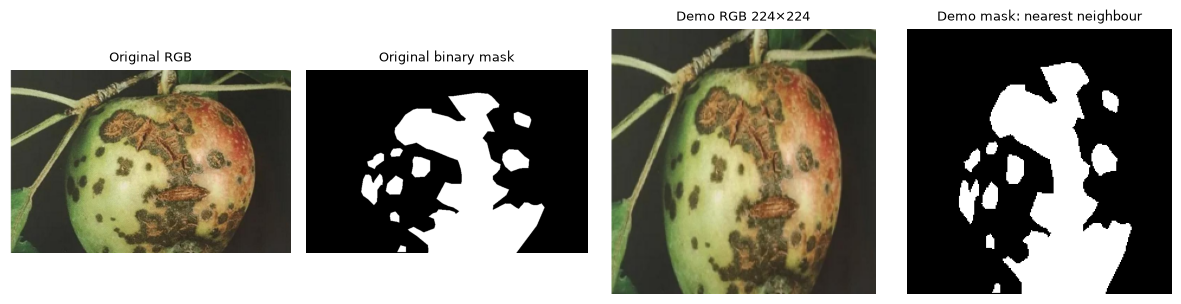

Resized mask values: [0, 1]


In [10]:
def resize_pair(rgb, mask, size=(224,224)):
    if rgb.size != mask.size:
        raise ValueError('Input pair must already be aligned')
    image_out = rgb.resize(size,Image.Resampling.BILINEAR)
    mask_out = mask.resize(size,Image.Resampling.NEAREST)
    assert image_out.size==mask_out.size==size
    assert set(np.unique(np.asarray(mask_out))).issubset({0,1})
    return image_out,mask_out

rgb, mask = load_training_pair(examples.iloc[0].to_dict(),DATA_ROOT)
resized_rgb, resized_mask = resize_pair(rgb,mask)
fig,axes=plt.subplots(1,4,figsize=(12,3))
for ax,obj,title in zip(axes,[rgb,mask,resized_rgb,resized_mask],['Original RGB','Original binary mask','Demo RGB 224×224','Demo mask: nearest neighbour']):
    ax.imshow(obj,cmap='gray' if obj.mode!='RGB' else None)
    ax.set_title(title,fontsize=9);ax.axis('off')
fig.tight_layout();fig.savefig(ART/'figures'/'paired_resize_demo.png',dpi=110)
plt.show();plt.close(fig)
print('Resized mask values:',np.unique(np.asarray(resized_mask)).tolist())

## 10. Handover and actual execution record
Next: review all draft exclusions/duplicates and confirm both class mappings before freezing; decide team contributions, hypothesis/tolerance, lesion mechanism, matched baselines, transforms and training seeds. Training, tuning, inference evaluation and literature comparison have not been implemented in Day 1.

AI assistance: Codex helped read the task sheet, inspect the official release, implement the notebook and run integrity/protocol checks. Students must review the code and understand it before submission. No model-version identifier is invented. Notebook assertions check data access permissions and role/split consistency; the execution record below reports this run only.

In [ ]:
summary = {'run_at':RUN_AT,'elapsed_seconds':round(time.perf_counter()-START_TIME,2),
           'dataset_version':dataset_info['version'],'checksum_status':dataset_info['checksum_status'],
           'subset':{'hosts':int(index.host.nunique()),'classes':len(classes),'images':len(index)},
           'audit':audit_summary,'manifest_status':protocol['status'],
           'blockers':protocol['freeze_blockers'],
           'outputs':['artifacts/metadata','artifacts/audit','artifacts/splits','artifacts/figures'],
           'not_done':['near-duplicate audit','team protocol freeze','model training','hyperparameter search','test performance'],
           'ai_assistance':{'tool':'Codex','model_version':'not recorded',
                            'tasks':['task-sheet and source inspection','Day 1 notebook implementation','data integrity and protocol checks']}}
save_json(ART/'metadata'/'execution_summary.json',summary)
display(summary)

{'run_at': '2026-11-11T22:37:49.184325+08:00',
 'elapsed_seconds': 56.19,
 'dataset_version': 'v7',
 'checksum_status': 'verified',
 'subset': {'hosts': 9, 'classes': 43, 'images': 4349},
 'audit': {'images': 4349,
  'hosts': 9,
  'classes': 43,
  'unreadable_images': 0,
  'mask_issues': 10,
  'file_duplicate_groups': 161,
  'pixel_duplicate_groups': 162,
  'cross_partition_duplicate_images': 151,
  'near_duplicate_check': 'not performed; unresolved near-duplicate leakage is a limitation',
  'pixel_hash_policy': 'EXIF transpose, RGB, original oriented dimensions plus raw pixel bytes; no resizing'},
 'manifest_status': 'draft',
 'blockers': ['Cross-partition exact duplicate groups unresolved',
  'Team review and explicit protocol freeze pending',
  'Training-mask exclusions/alignment require review'],
 'outputs': ['artifacts/metadata',
  'artifacts/audit',
  'artifacts/splits',
  'artifacts/figures'],
 'not_done': ['near-duplicate audit',
  'team protocol freeze',
  'model training',
  